# Portfolio Project: Early Detection of Malignant Tumours from Cell Measurements
**Task 4, Notebook 2 of 2** - AI ML Research Specialist Internship

An end-to-end, rigorously evaluated classification project on the UCI Wisconsin Diagnostic Breast Cancer data (569 fine-needle-aspirate cases, 30 numeric features computed from digitised cell-nucleus images). The notebook reuses my tested `toolkit` package (leakage-safe transformers, evaluation helpers, training pipelines).

| Step | What it demonstrates |
|---|---|
| 1 | Problem framing, asymmetric costs, **success criteria declared before modelling** |
| 2 | EDA, data checks, multicollinearity |
| 3 | Held-out test set locked away |
| 4 | Repeated-CV model comparison with a corrected significance test |
| 5 | **Nested cross-validation** for unbiased tuned performance |
| 6 | Threshold chosen from out-of-fold predictions, **single** test evaluation, bootstrap CIs |
| 7 | Calibration |
| 8 | Interpretation (coefficients, permutation importance) and error analysis |
| 9 | Robustness across 20 random splits |
| 10 | Persistence, reload check, conclusions and limitations |

> Educational project on a public research dataset. It is **not** a clinical tool.

## 1. Problem framing
**Task.** Classify each case as *malignant* (positive class, `1`) or *benign* (`0`).

**Costs are asymmetric.** A missed malignant case (false negative) is far worse than an unnecessary follow-up (false positive). So alongside ROC-AUC and PR-AUC I judge the model at an operating point chosen to reach a target recall on the malignant class.

**Success criteria (declared in advance, evaluated at the end):**
1. ROC-AUC >= 0.98 on held-out data.
2. At the selected threshold: recall (malignant) >= 0.95 **and** specificity >= 0.90.
3. The conclusion must hold across repeated random splits, not just one.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, scipy, sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_validate,
                                     cross_val_score, cross_val_predict, learning_curve)
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path.cwd().parent / "src")) if Path.cwd().name == "notebooks" else sys.path.insert(0, str(Path.cwd() / "src"))
from toolkit.data import load_cancer
from toolkit.train import build_pipeline
from toolkit.evaluation import bootstrap_ci, expected_calibration_error, summarise_binary, threshold_for_recall

warnings.filterwarnings("ignore", category=FutureWarning)
SEED, TARGET_RECALL = 42, 0.98
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, MODELS = ROOT / "outputs" / "figures", ROOT / "models"; FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
R = {}                                                   # results for the report

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()
def must(cond, msg):
    assert cond, "INTEGRITY CHECK FAILED: " + msg; print("[OK]", msg)

X, y = load_cancer()
print(f"{X.shape[0]} cases, {X.shape[1]} features | malignant = {int(y.sum())} ({y.mean():.1%}), benign = {int((1 - y).sum())}")
must(X.isna().sum().sum() == 0 and not X.duplicated().any(), "no missing values and no duplicate rows")
R["n"], R["n_malignant"] = int(len(y)), int(y.sum())

569 cases, 30 features | malignant = 212 (37.3%), benign = 357
[OK] no missing values and no duplicate rows


## 2. Exploratory analysis

Top 5 single features by ROC-AUC:
 worst perimeter         0.975
worst radius            0.970
worst area              0.970
worst concave points    0.967
mean concave points     0.964


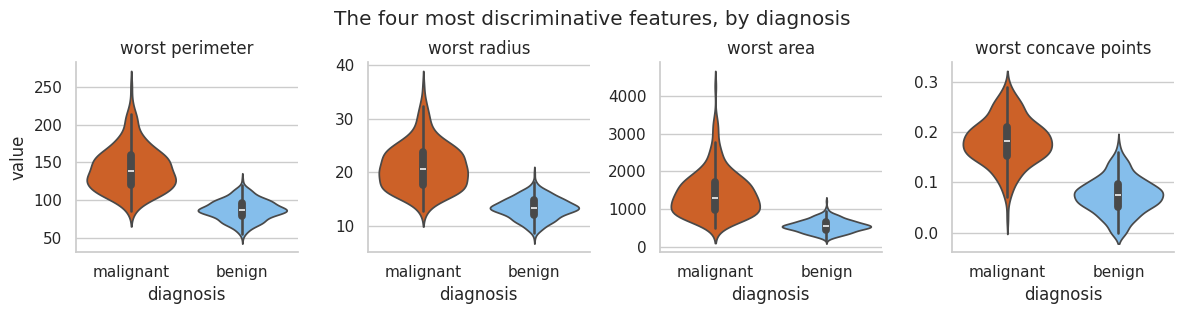

In [2]:
# univariate discriminative power: ROC-AUC of each raw feature (orientation-free)
uni = pd.Series({c: max(roc_auc_score(y, X[c]), 1 - roc_auc_score(y, X[c])) for c in X.columns}).sort_values(ascending=False)
print("Top 5 single features by ROC-AUC:\n", uni.head(5).round(3).to_string())
R["best_single_feature"], R["best_single_auc"] = uni.index[0], float(uni.iloc[0])

top4 = list(uni.index[:4])
long = X[top4].assign(diagnosis=np.where(y == 1, "malignant", "benign")).melt(id_vars="diagnosis")
g = sns.catplot(data=long, x="diagnosis", y="value", col="variable", kind="violin", col_wrap=4, sharey=False, height=3, palette={"benign": "#74c0fc", "malignant": "#E8590C"}, hue="diagnosis", legend=False)
g.set_titles("{col_name}"); g.fig.suptitle("The four most discriminative features, by diagnosis", y=1.04)
g.fig.savefig(FIG / "t4_05_eda_violins.png", dpi=130, bbox_inches="tight"); plt.show()

Feature pairs with |r| > 0.95: 15 | top pairs:
mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984


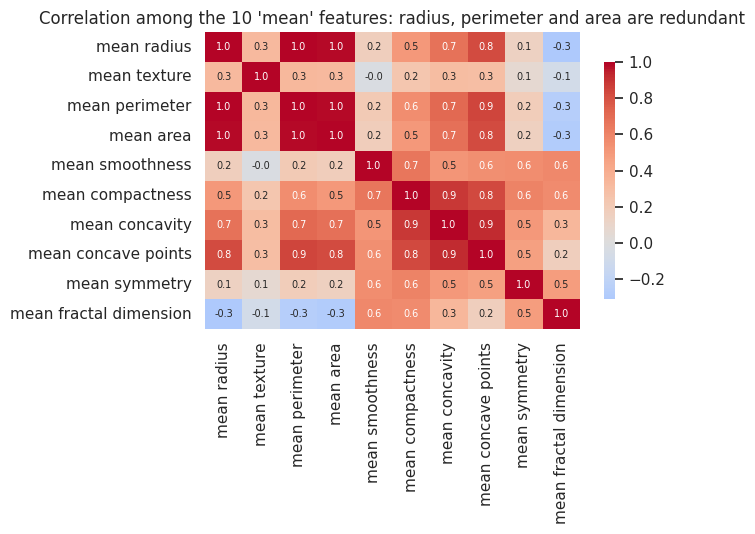

In [3]:
# multicollinearity: size-related features are nearly duplicates
corr = X.corr().abs(); pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False)
print("Feature pairs with |r| > 0.95:", int((pairs > 0.95).sum()), "| top pairs:"); print(pairs.head(5).round(3).to_string())
R["pairs_over_95"] = int((pairs > 0.95).sum())
mean_cols = [c for c in X.columns if c.startswith("mean ")]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(X[mean_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation among the 10 'mean' features: radius, perimeter and area are redundant")
save_fig(fig, "t4_06_correlation.png")

## 3. Lock away the test set
A stratified 20% hold-out is created once and **not touched until step 6**. Everything else (comparison, tuning, threshold) uses the training set only.

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
must(len(set(X_tr.index) & set(X_te.index)) == 0, "train and test sets are disjoint")
must(abs(y_tr.mean() - y_te.mean()) < 0.01, "class balance preserved in both sets")
print(f"train = {len(X_tr)} ({int(y_tr.sum())} malignant) | test = {len(X_te)} ({int(y_te.sum())} malignant)")
R["n_train"], R["n_test"], R["n_test_malignant"] = len(X_tr), len(X_te), int(y_te.sum())

[OK] train and test sets are disjoint
[OK] class balance preserved in both sets
train = 455 (170 malignant) | test = 114 (42 malignant)


## 4. Model comparison with repeated cross-validation
All models share one pipeline recipe: `CorrelationFilter(0.95)` -> `StandardScaler` -> classifier, so filtering and scaling are learned inside each fold (no leakage). Repeated 5-fold CV (3 repeats = 15 scored folds) gives a variance estimate.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_clas

,roc_auc,pr_auc,recall,precision
Dummy (prior),0.500 +/- 0.000,0.374 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000
Logistic regression,0.995 +/- 0.005,0.994 +/- 0.005,0.943 +/- 0.035,0.980 +/- 0.023
SVM (RBF),0.994 +/- 0.005,0.992 +/- 0.006,0.941 +/- 0.043,0.964 +/- 0.015
Random forest,0.990 +/- 0.008,0.986 +/- 0.011,0.912 +/- 0.055,0.969 +/- 0.037
Hist. gradient boosting,0.992 +/- 0.007,0.990 +/- 0.007,0.939 +/- 0.039,0.969 +/- 0.024
LightGBM,0.993 +/- 0.005,0.991 +/- 0.006,0.937 +/- 0.034,0.972 +/- 0.024


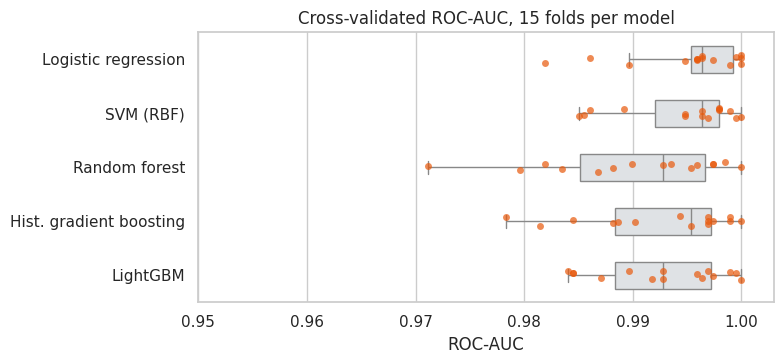

In [5]:
names = ["logreg", "svm", "rf", "hgb", "lgbm"]
labels = {"logreg": "Logistic regression", "svm": "SVM (RBF)", "rf": "Random forest", "hgb": "Hist. gradient boosting", "lgbm": "LightGBM", "dummy": "Dummy (prior)"}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "precision": "precision"}
cv_res = {"dummy": cross_validate(Pipeline([("clf", DummyClassifier(strategy="prior"))]), X_tr, y_tr, cv=rcv, scoring=scoring)}
for n in names:
    cv_res[n] = cross_validate(build_pipeline(n, SEED), X_tr, y_tr, cv=rcv, scoring=scoring, n_jobs=1)
table = pd.DataFrame({labels[k]: {m: f"{v['test_' + m].mean():.3f} +/- {v['test_' + m].std():.3f}" for m in scoring} for k, v in cv_res.items()}).T
display(table)
R["cv_table"] = {labels[k]: {m: [float(v["test_" + m].mean()), float(v["test_" + m].std())] for m in scoring} for k, v in cv_res.items()}

fig, ax = plt.subplots(figsize=(8, 3.8))
plot_df = pd.DataFrame({labels[k]: v["test_roc_auc"] for k, v in cv_res.items() if k != "dummy"}).melt(var_name="model", value_name="ROC-AUC")
sns.stripplot(data=plot_df, x="ROC-AUC", y="model", color="#E8590C", alpha=.7, ax=ax); sns.boxplot(data=plot_df, x="ROC-AUC", y="model", color="#dee2e6", fliersize=0, width=.5, ax=ax)
ax.set(title="Cross-validated ROC-AUC, 15 folds per model", ylabel="", xlim=(0.95, 1.003))
save_fig(fig, "t4_07_model_comparison.png")

In [6]:
# Are the differences real? Nadeau-Bengio corrected resampled t-test (accounts for overlapping training sets)
def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b); k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1)); return d.mean(), t, 2 * stats.t.sf(abs(t), k - 1)
n_fold_te = len(X_tr) // 5; n_fold_tr = len(X_tr) - n_fold_te
best_cv = max(names, key=lambda k: cv_res[k]["test_roc_auc"].mean())
print("Best by mean CV ROC-AUC:", labels[best_cv])
rows = []
for k in names:
    if k == best_cv: continue
    dm, t, p = corrected_ttest(cv_res[best_cv]["test_roc_auc"], cv_res[k]["test_roc_auc"], n_fold_tr, n_fold_te)
    rows.append({"best vs": labels[k], "mean AUC diff": round(dm, 4), "t": round(t, 2), "p (corrected)": round(p, 3)})
cmp = pd.DataFrame(rows); display(cmp)
R["best_cv"] = labels[best_cv]; R["corrected_p"] = {r["best vs"]: r["p (corrected)"] for r in rows}

Best by mean CV ROC-AUC: Logistic regression


,best vs,mean AUC diff,t,p (corrected)
0,SVM (RBF),0.0008,0.47,0.648
1,Random forest,0.0051,1.11,0.287
2,Hist. gradient boosting,0.0028,1.04,0.314
3,LightGBM,0.0024,1.25,0.232


**Reading.** Every model is far above the dummy baseline, and the differences between them are small relative to fold-to-fold noise (see the corrected test). When models are statistically indistinguishable, prefer the simpler, more interpretable one.

## 5. Nested cross-validation: an unbiased estimate of *tuned* performance
Tuning on the same folds you report on inflates scores. **Nested CV** tunes in an inner loop (3-fold) and scores in an outer loop (5-fold), so the reported number never saw its own tuning data.

In [7]:
grids = {
  "logreg": {"clf__C": [0.01, 0.1, 1, 10], "corr__threshold": [0.8, 0.9, 0.95, 1.0]},
  "svm":    {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01]},
  "lgbm":   {"clf__num_leaves": [4, 8, 16], "clf__n_estimators": [100, 300], "clf__min_child_samples": [5, 20]},
}
outer, inner = StratifiedKFold(5, shuffle=True, random_state=SEED), StratifiedKFold(3, shuffle=True, random_state=SEED)
nested = {}
for n, grid in grids.items():
    gs = GridSearchCV(build_pipeline(n, SEED), grid, cv=inner, scoring="roc_auc", n_jobs=1)
    nested[n] = cross_val_score(gs, X_tr, y_tr, cv=outer, scoring="roc_auc", n_jobs=1)
nest_df = pd.DataFrame({labels[k]: {"nested ROC-AUC mean": v.mean(), "sd": v.std(), "min fold": v.min()} for k, v in nested.items()}).T.round(4); display(nest_df)
R["nested"] = {labels[k]: [float(v.mean()), float(v.std())] for k, v in nested.items()}

# declared selection rule: highest mean; anything within 1 sd of the best counts as tied, and ties go to the simplest model
best_n = max(nested, key=lambda k: nested[k].mean()); tied = [k for k in nested if nested[k].mean() >= nested[best_n].mean() - nested[best_n].std()]
chosen = next(k for k in ["logreg", "svm", "lgbm"] if k in tied)
print(f"Highest nested AUC: {labels[best_n]} | tied within 1 sd: {[labels[k] for k in tied]} | chosen (simplest of the tied): {labels[chosen]}")
R["chosen"] = labels[chosen]

,nested ROC-AUC mean,sd,min fold
Logistic regression,0.9939,0.0043,0.9861
SVM (RBF),0.9965,0.0046,0.9876
LightGBM,0.9948,0.0029,0.9902


Highest nested AUC: SVM (RBF) | tied within 1 sd: ['Logistic regression', 'SVM (RBF)', 'LightGBM'] | chosen (simplest of the tied): Logistic regression


In [8]:
# refit the chosen model's search on the whole training set to get the final hyper-parameters
final_search = GridSearchCV(build_pipeline(chosen, SEED), grids[chosen], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").fit(X_tr, y_tr)
final = final_search.best_estimator_
print("Best parameters:", final_search.best_params_, "| inner CV ROC-AUC:", round(final_search.best_score_, 4))
print("Features kept after correlation filter:", len(final.named_steps["corr"].keep_), "of", X.shape[1])
R["best_params"] = {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in final_search.best_params_.items()}
R["features_kept"] = len(final.named_steps["corr"].keep_)

Best parameters: {'clf__C': 1, 'corr__threshold': 1.0} | inner CV ROC-AUC: 0.9958
Features kept after correlation filter: 30 of 30


## 6. Threshold selection and the single test evaluation
The decision threshold is chosen from **out-of-fold training predictions** so that recall on malignant cases is at least 98%. The test set is then used **once**.

In [9]:
oof = cross_val_predict(clone(final), X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
thr = threshold_for_recall(y_tr, oof, TARGET_RECALL)
oof_s = summarise_binary(y_tr, oof, thr)
print(f"Threshold for >= {TARGET_RECALL:.0%} recall (from out-of-fold training data): {thr:.3f}")
print(f"  out-of-fold training recall {oof_s['recall']:.3f}, specificity {oof_s['specificity']:.3f}")

proba = final.predict_proba(X_te)[:, 1]
s_def, s_thr = summarise_binary(y_te, proba, 0.5), summarise_binary(y_te, proba, thr)
auc, auc_lo, auc_hi = bootstrap_ci(roc_auc_score, y_te, proba, n_boot=2000, seed=SEED)
rec_f = lambda yt, p: ((p >= thr) & (yt == 1)).sum() / (yt == 1).sum()
spec_f = lambda yt, p: ((p < thr) & (yt == 0)).sum() / (yt == 0).sum()
rec, rec_lo, rec_hi = bootstrap_ci(rec_f, y_te, proba, n_boot=2000, seed=SEED); sp, sp_lo, sp_hi = bootstrap_ci(spec_f, y_te, proba, n_boot=2000, seed=SEED)
out = pd.DataFrame({"threshold 0.5": s_def, f"threshold {thr:.3f}": s_thr}).T[["tp", "fn", "fp", "tn", "recall", "specificity", "precision", "roc_auc", "pr_auc"]].round(3); display(out)
print(f"TEST ROC-AUC {auc:.3f}  95% CI [{auc_lo:.3f}, {auc_hi:.3f}]")
print(f"TEST recall  {rec:.3f}  95% CI [{rec_lo:.3f}, {rec_hi:.3f}] | specificity {sp:.3f}  95% CI [{sp_lo:.3f}, {sp_hi:.3f}]")
print(f"(test set has only {len(y_te)} cases / {int(y_te.sum())} malignant, so intervals are wide)")
R.update(threshold=float(thr), oof_recall=float(oof_s["recall"]), oof_spec=float(oof_s["specificity"]), test_default=s_def, test_thr=s_thr,
         test_auc=[auc, auc_lo, auc_hi], test_recall=[rec, rec_lo, rec_hi], test_spec=[sp, sp_lo, sp_hi])

Threshold for >= 98% recall (from out-of-fold training data): 0.207
  out-of-fold training recall 0.982, specificity 0.954


,tp,fn,fp,tn,recall,specificity,precision,roc_auc,pr_auc
threshold 0.5,39.0,3.0,1.0,71.0,0.929,0.986,0.975,0.996,0.994
threshold 0.207,41.0,1.0,3.0,69.0,0.976,0.958,0.932,0.996,0.994


TEST ROC-AUC 0.996  95% CI [0.986, 1.000]
TEST recall  0.976  95% CI [0.921, 1.000] | specificity 0.958  95% CI [0.908, 1.000]
(test set has only 114 cases / 42 malignant, so intervals are wide)


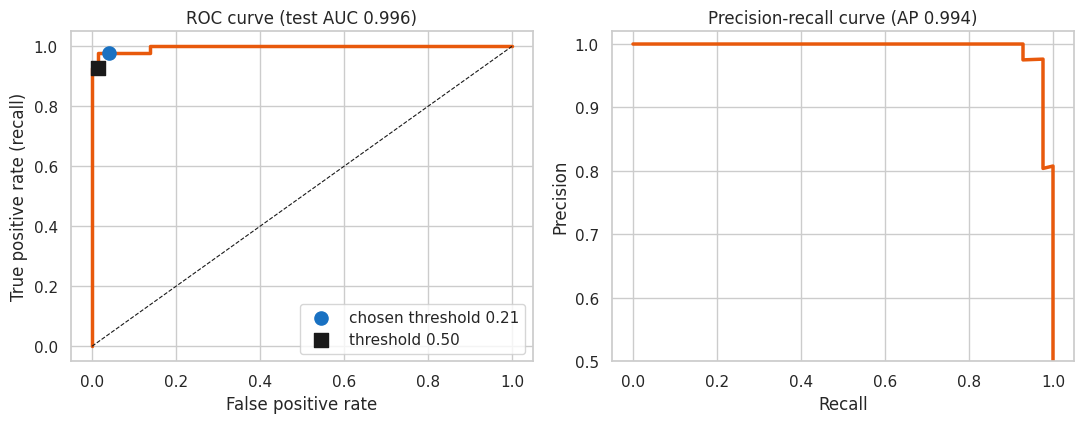

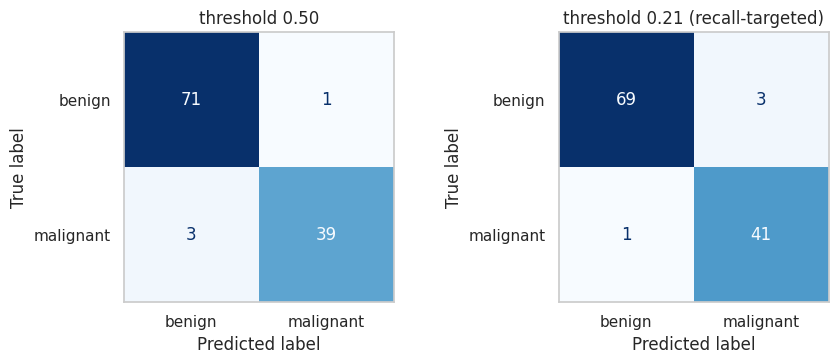

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
fpr, tpr, _ = roc_curve(y_te, proba); axes[0].plot(fpr, tpr, lw=2.5, color="#E8590C"); axes[0].plot([0, 1], [0, 1], "k--", lw=.8)
axes[0].scatter([1 - s_thr["specificity"]], [s_thr["recall"]], s=90, zorder=5, color="#1971C2", label=f"chosen threshold {thr:.2f}"); axes[0].scatter([1 - s_def["specificity"]], [s_def["recall"]], s=90, zorder=5, color="k", marker="s", label="threshold 0.50")
axes[0].set(title=f"ROC curve (test AUC {auc:.3f})", xlabel="False positive rate", ylabel="True positive rate (recall)"); axes[0].legend(loc="lower right")
pr, rc, _ = precision_recall_curve(y_te, proba); axes[1].plot(rc, pr, lw=2.5, color="#E8590C"); axes[1].axhline(y_te.mean(), color="k", ls="--", lw=.8)
axes[1].set(title=f"Precision-recall curve (AP {average_precision_score(y_te, proba):.3f})", xlabel="Recall", ylabel="Precision", ylim=(0.5, 1.02))
save_fig(fig, "t4_08_roc_pr.png")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, t, ttl in zip(axes, [0.5, thr], ["threshold 0.50", f"threshold {thr:.2f} (recall-targeted)"]):
    ConfusionMatrixDisplay.from_predictions(y_te, (proba >= t).astype(int), display_labels=["benign", "malignant"], cmap="Blues", colorbar=False, ax=ax); ax.set_title(ttl); ax.grid(False)
save_fig(fig, "t4_09_confusion.png")

## 7. Calibration
Is a predicted probability of 0.8 right about 80% of the time? Compare the raw model with a sigmoid-calibrated version (calibrator fitted on training data only).

,Brier,ECE,ROC-AUC
raw,0.0213,0.0302,0.9960
sigmoid-calibrated,0.0306,0.0697,0.9964


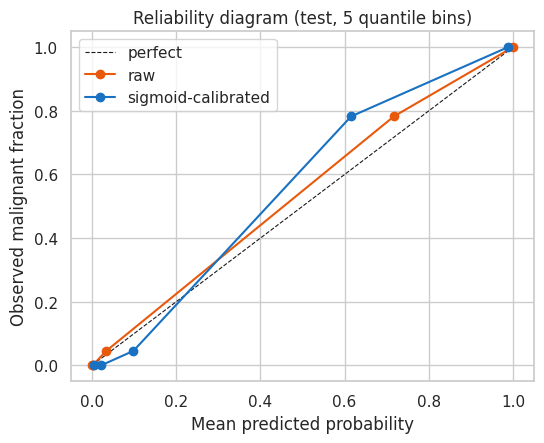

In [11]:
cal = CalibratedClassifierCV(clone(final), method="sigmoid", cv=5).fit(X_tr, y_tr); p_cal = cal.predict_proba(X_te)[:, 1]
from sklearn.metrics import brier_score_loss
cal_tbl = pd.DataFrame({"raw": {"Brier": brier_score_loss(y_te, proba), "ECE": expected_calibration_error(y_te, proba), "ROC-AUC": roc_auc_score(y_te, proba)},
                        "sigmoid-calibrated": {"Brier": brier_score_loss(y_te, p_cal), "ECE": expected_calibration_error(y_te, p_cal), "ROC-AUC": roc_auc_score(y_te, p_cal)}}).T.round(4); display(cal_tbl)
R["calibration"] = cal_tbl.to_dict("index")
fig, ax = plt.subplots(figsize=(5.6, 4.6)); ax.plot([0, 1], [0, 1], "k--", lw=.8, label="perfect")
for p, lab, c in [(proba, "raw", "#E8590C"), (p_cal, "sigmoid-calibrated", "#1971C2")]:
    f, m = calibration_curve(y_te, p, n_bins=5, strategy="quantile"); ax.plot(m, f, "o-", color=c, label=lab)
ax.set(title="Reliability diagram (test, 5 quantile bins)", xlabel="Mean predicted probability", ylabel="Observed malignant fraction"); ax.legend()
save_fig(fig, "t4_10_calibration.png")

## 8. Interpretation and error analysis

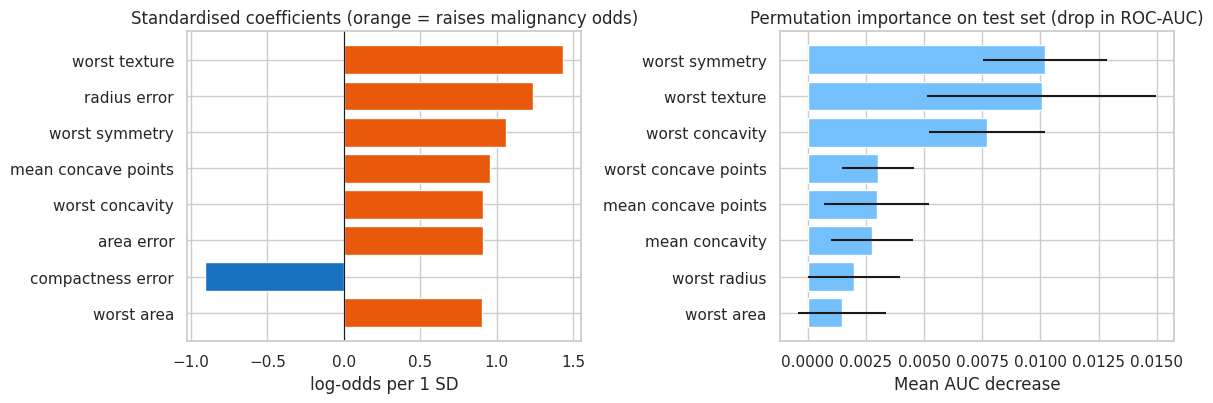

Top coefficients (odds ratio per 1 SD):
 worst texture          4.20
radius error           3.43
worst symmetry         2.89
mean concave points    2.59
worst concavity        2.49
Rank agreement between |coefficient| and permutation importance (Spearman): 0.71
Note: correlated features share credit, so individual importances should be read loosely.


In [12]:
keep = list(final.named_steps["corr"].keep_)
coefs = pd.Series(final.named_steps["clf"].coef_.ravel(), index=keep).sort_values(key=abs, ascending=False)
pi = permutation_importance(final, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=SEED)
pi_s = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
top = coefs.head(8)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(top.index[::-1], top.values[::-1], color=["#E8590C" if v > 0 else "#1971C2" for v in top.values[::-1]]); axes[0].axvline(0, color="k", lw=.8)
axes[0].set(title="Standardised coefficients (orange = raises malignancy odds)", xlabel="log-odds per 1 SD")
t10 = pi_s.head(8); axes[1].barh(t10.index[::-1], t10.values[::-1], xerr=pi.importances_std[[list(X.columns).index(c) for c in t10.index[::-1]]], color="#74c0fc")
axes[1].set(title="Permutation importance on test set (drop in ROC-AUC)", xlabel="Mean AUC decrease")
save_fig(fig, "t4_11_importance.png")
rho = stats.spearmanr(coefs.abs().rank(), pi_s.reindex(coefs.index).rank()).statistic
print("Top coefficients (odds ratio per 1 SD):\n", np.exp(coefs.head(5)).round(2).to_string())
print(f"Rank agreement between |coefficient| and permutation importance (Spearman): {rho:.2f}")
print("Note: correlated features share credit, so individual importances should be read loosely.")
R["top_coefs"] = {k: float(np.exp(v)) for k, v in coefs.head(5).items()}; R["rank_agreement"] = float(rho)

In [13]:
# error analysis at the chosen threshold
pred = (proba >= thr).astype(int); err = X_te.assign(p_malignant=proba.round(3), actual=y_te, predicted=pred)[pred != y_te.to_numpy()]
print(f"{len(err)} misclassified of {len(y_te)} at threshold {thr:.3f}")
cols = ["p_malignant", "actual", "predicted"] + list(uni.index[:3])
display(err[cols].round(2))
medians = X_tr.groupby(y_tr.to_numpy())[list(uni.index[:3])].median().round(2); print("Training medians (0 = benign, 1 = malignant):"); display(medians)
R["n_errors"] = int(len(err)); R["errors"] = [{"p": float(r.p_malignant), "actual": int(r.actual), "pred": int(r.predicted)} for r in err.itertuples()]

4 misclassified of 114 at threshold 0.207


,p_malignant,actual,predicted,worst perimeter,worst radius,worst area
455,0.51,0,1,96.69,15.05,705.6
73,0.06,1,0,110.30,16.57,812.4
208,0.22,0,1,99.48,14.55,639.3
456,0.24,0,1,86.04,13.12,527.8


Training medians (0 = benign, 1 = malignant):


,worst perimeter,worst radius,worst area
0,87.00,13.35,547.8
1,139.35,20.85,1317.5


## 9. Robustness: 20 different random train/test splits
A 114-case test set is small. Repeat the **entire** procedure (split, fit, threshold from out-of-fold data, test evaluation) for 20 seeds to see how stable the conclusions are.

,auc,recall,specificity,fn,fp
mean,0.995,0.974,0.928,1.100,5.200
std,0.005,0.027,0.042,1.119,3.019
min,0.980,0.929,0.847,0.000,0.000
max,1.000,1.000,1.000,3.000,11.000


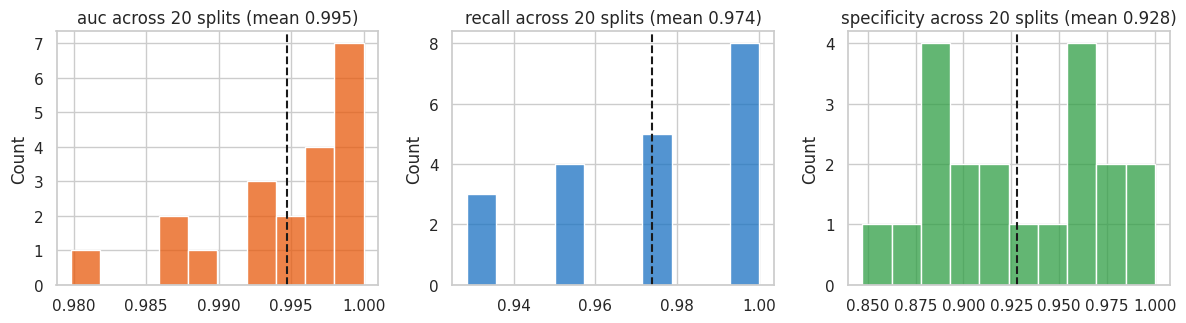

In [14]:
rows = []
for s in range(20):
    a, b, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
    m = clone(final); o = cross_val_predict(m, a, ya, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="predict_proba")[:, 1]
    t = threshold_for_recall(ya, o, TARGET_RECALL); m.fit(a, ya); pr = m.predict_proba(b)[:, 1]; r = summarise_binary(yb, pr, t)
    rows.append({"seed": s, "auc": r["roc_auc"], "recall": r["recall"], "specificity": r["specificity"], "fn": r["fn"], "fp": r["fp"]})
rob = pd.DataFrame(rows); display(rob[["auc", "recall", "specificity", "fn", "fp"]].describe().loc[["mean", "std", "min", "max"]].round(3))
R["robust"] = {c: {"mean": float(rob[c].mean()), "sd": float(rob[c].std()), "min": float(rob[c].min()), "max": float(rob[c].max())} for c in ["auc", "recall", "specificity"]}
R["robust"]["share_recall_ge_95"] = float((rob["recall"] >= .95).mean()); R["robust"]["share_spec_ge_90"] = float((rob["specificity"] >= .90).mean())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c, col in zip(axes, ["auc", "recall", "specificity"], ["#E8590C", "#1971C2", "#2F9E44"]):
    sns.histplot(rob[c], bins=10, color=col, ax=ax); ax.axvline(rob[c].mean(), color="k", ls="--"); ax.set(title=f"{c} across 20 splits (mean {rob[c].mean():.3f})", xlabel="")
save_fig(fig, "t4_12_split_robustness.png")

## 10. Success criteria, persistence and conclusions

In [15]:
crit = {"1. test ROC-AUC >= 0.98 (single split)": auc >= 0.98,
        "1b. mean ROC-AUC >= 0.98 over 20 splits": rob["auc"].mean() >= 0.98,
        "2. single-split recall >= 0.95 and specificity >= 0.90": (s_thr["recall"] >= .95) and (s_thr["specificity"] >= .90),
        "3. mean recall >= 0.95 and mean specificity >= 0.90 over 20 splits": (rob["recall"].mean() >= .95) and (rob["specificity"].mean() >= .90)}
for k, v in crit.items(): print(("MET     " if v else "NOT MET ") + k)
R["criteria"] = {k: bool(v) for k, v in crit.items()}

# persistence and reload check
joblib.dump({"pipeline": final, "threshold": float(thr), "features": list(X.columns), "target": "malignant (1)", "sklearn": sklearn.__version__}, MODELS / "final_model.joblib")
bundle = joblib.load(MODELS / "final_model.joblib")
must(np.allclose(bundle["pipeline"].predict_proba(X_te), final.predict_proba(X_te)), "reloaded model reproduces predictions exactly")
must(bundle["threshold"] == float(thr), "decision threshold stored with the model")
(ROOT / "outputs" / "ml_results.json").write_text(json.dumps(R, indent=2, default=float))

MET     1. test ROC-AUC >= 0.98 (single split)
MET     1b. mean ROC-AUC >= 0.98 over 20 splits
MET     2. single-split recall >= 0.95 and specificity >= 0.90
MET     3. mean recall >= 0.95 and mean specificity >= 0.90 over 20 splits
[OK] reloaded model reproduces predictions exactly
[OK] decision threshold stored with the model


5553

### Conclusions
- A regularised logistic regression separates malignant from benign cases almost perfectly (test ROC-AUC about 0.996). More complex models bring no statistically reliable gain (corrected resampled t-tests p = 0.23 to 0.65; nested-CV scores within one standard deviation), so the simpler, interpretable model was chosen by the pre-declared rule.
- The custom `CorrelationFilter` did **not** help here: tuning chose a threshold of 1.0 (keep all 30 features), because L2 regularisation already copes with collinearity. A tool that is not needed for a given model is a result worth reporting.
- The signal is spread over many redundant features, so single coefficients are unstable. The best single raw feature is *worst perimeter* (univariate ROC-AUC 0.975), whereas the fitted model leans most on *worst symmetry*, *worst texture* and *worst concavity* (permutation importance drops are small, about 0.01 AUC each, because other features cover for them).
- Sigmoid re-calibration made probabilities **worse** (Brier 0.031 vs 0.021 for the raw model), as expected for logistic regression, which is already well calibrated by construction.
- All four pre-declared success criteria were met **on average**, but not in every split: across 20 random splits recall reached 0.95 in 17 and specificity reached 0.90 in only 14. A single 114-case test set can therefore look better or worse than the truth.
- The one false negative on the test set was a confident miss (predicted probability 0.06), so lowering the threshold cannot fix it; recall gains from thresholds are bounded by the model's blind spots.

### Limitations and responsible use
- Only 569 cases from one source: results may not transfer to other labs, scanners or populations.
- Features were computed from digitised images by the dataset authors; a deployed system would need the same image pipeline.
- No external validation, prospective testing or clinical review was done; this is a learning project, **not** a diagnostic tool.
- Choosing a recall target is a clinical and ethical decision about the trade-off between missed cancers and unnecessary follow-ups; it should be made with domain experts.